# Step 4: RFM features

**Goal:** turn each snapshot's feature rows into one row per customer with three numbers.

| Feature | Meaning | Definition used |
|---|---|---|
| **R**ecency | how recently they bought | whole days from their last *purchase* to the **cutoff** (small = recent) |
| **F**requency | how often they buy | number of distinct purchase invoices in the feature window |
| **M**onetary | how much they spend | **net** money kept in the feature window (purchases minus returns) |

Notes:
- Recency is measured from the cutoff, not from today, so train and test are comparable.
- Returns do **not** count as purchases for Recency/Frequency, but they **do** reduce Monetary (same netting decision as the target).

The logic is in `src/step4_rfm.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from step3_split import load_ledger, make_snapshot, TRAIN_CUTOFF, TEST_CUTOFF
from step4_rfm import build_rfm

pd.set_option("display.width", 160)
ledger = load_ledger()
train = make_snapshot(ledger, TRAIN_CUTOFF)
test = make_snapshot(ledger, TEST_CUTOFF)
rfm_train, rfm_test = build_rfm(train), build_rfm(test)
rfm_train.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,156,2,169.36
12347,31,1,611.53
12348,65,1,222.16
12349,34,3,2646.99
12351,2,1,300.93


## 1. Check by hand: one customer

Pick a customer with a return and recompute R, F and M from the raw rows. If this matches, the function is doing what we think.

In [2]:
rows = train.feature_rows
cust = rows[rows["IsReturn"]]["Customer ID"].iloc[0]
r = rows[rows["Customer ID"] == cust]
display(r[["Invoice", "InvoiceDate", "StockCode", "Quantity", "Price", "TotalPrice", "IsReturn"]].head(12))

p = r[~r["IsReturn"]]
by_hand = {
    "Recency": (TRAIN_CUTOFF - p["InvoiceDate"].max().normalize()).days,
    "Frequency": p["Invoice"].nunique(),
    "Monetary": round(r["TotalPrice"].sum(), 2),
}
print("customer", cust)
print("by hand :", by_hand)
print("function:", rfm_train.loc[cust].round(2).to_dict())

,Invoice,InvoiceDate,StockCode,Quantity,Price,TotalPrice,IsReturn
330,C490283,2009-12-04 12:49:00,22072,-1,3.75,-3.75,True
331,C490283,2009-12-04 12:49:00,20914,-1,2.95,-2.95,True
332,C490283,2009-12-04 12:49:00,21231,-1,1.25,-1.25,True
333,C490283,2009-12-04 12:49:00,21232,-1,1.25,-1.25,True
334,C490283,2009-12-04 12:49:00,20747,-1,14.95,-14.95,True
335,506394,2010-04-29 13:20:00,22554,12,1.65,19.80,False
336,506394,2010-04-29 13:20:00,22555,12,1.65,19.80,False
337,506394,2010-04-29 13:20:00,22553,12,1.65,19.80,False
338,506394,2010-04-29 13:20:00,16156S,25,0.42,10.50,False
339,506394,2010-04-29 13:20:00,22052,25,0.42,10.50,False


customer 12349
by hand : {'Recency': 34, 'Frequency': 3, 'Monetary': np.float64(2646.99)}
function: {'Recency': 34.0, 'Frequency': 3.0, 'Monetary': 2646.99}


## 2. Distributions

All three are skewed: most customers are small and infrequent, a few are very large. Histograms use a log scale on the x-axis for F and M.

,Recency,Frequency,Monetary
count,4242.0,4242.0,4242.0
mean,87.6,4.3,1927.5
std,94.7,7.6,8336.7
min,1.0,1.0,-1663.1
25%,16.0,1.0,301.3
50%,48.0,2.0,671.1
75%,132.0,5.0,1637.1
max,365.0,176.0,318751.3


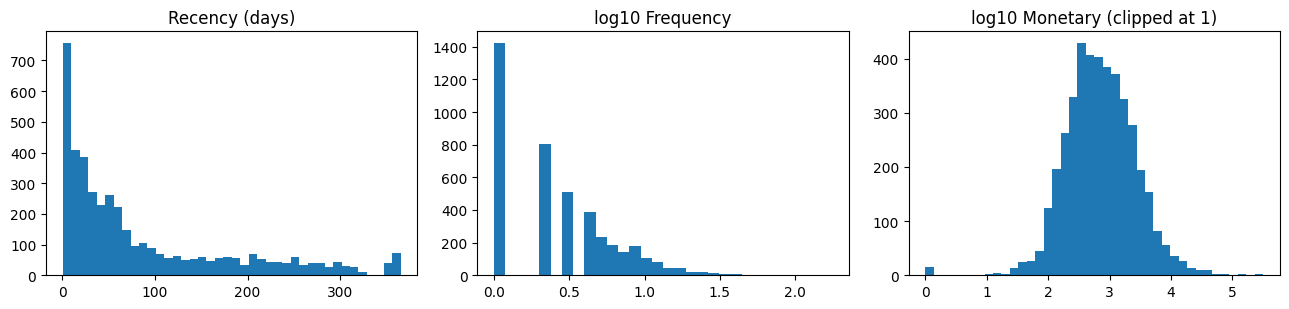

In [3]:
display(rfm_train.describe().round(1))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(rfm_train["Recency"], bins=40, color="tab:blue"); axes[0].set_title("Recency (days)")
axes[1].hist(np.log10(rfm_train["Frequency"]), bins=30, color="tab:blue"); axes[1].set_title("log10 Frequency")
axes[2].hist(np.log10(rfm_train["Monetary"].clip(lower=1)), bins=40, color="tab:blue"); axes[2].set_title("log10 Monetary (clipped at 1)")
plt.tight_layout()

A handful of customers have `Monetary <= 0`: they returned more in the feature window than they bought there (returning goods bought before the window).

In [4]:
print("train Monetary <= 0:", int((rfm_train['Monetary'] <= 0).sum()),
      "| test:", int((rfm_test['Monetary'] <= 0).sum()))
print("Frequency == 1 (one-time buyers) - train: {:.0%}, test: {:.0%}".format(
    (rfm_train['Frequency'] == 1).mean(), (rfm_test['Frequency'] == 1).mean()))

train Monetary <= 0: 14 | test: 9
Frequency == 1 (one-time buyers) - train: 34%, test: 36%


## 3. Do the features relate to the future spend?

Rank (Spearman) correlation with the target. Rank-based, because both sides are heavily skewed.

In [5]:
corr = pd.DataFrame({
    "train": rfm_train.assign(target=train.target).corr(method="spearman")["target"].drop("target"),
    "test": rfm_test.assign(target=test.target).corr(method="spearman")["target"].drop("target"),
}).round(3)
corr

,train,test
Recency,-0.360,-0.453
Frequency,0.534,0.540
Monetary,0.538,0.584


Average future spend by quartile of each feature (train). If a feature is useful, the bars should trend steadily.

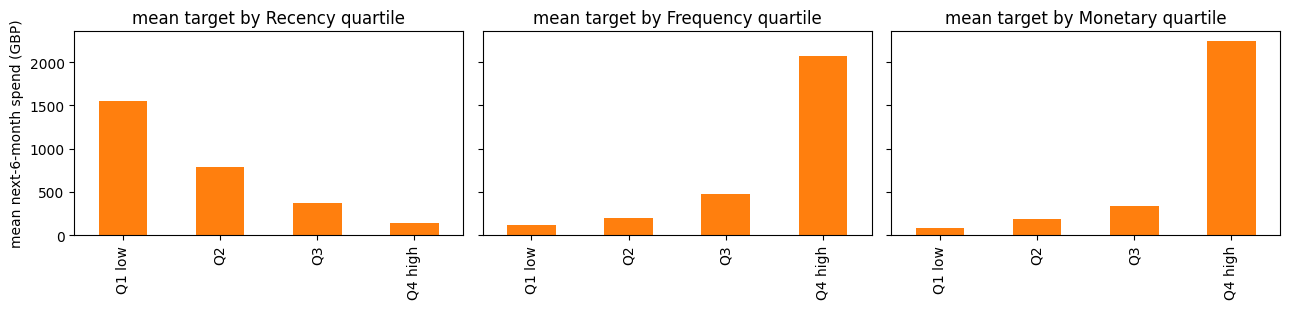

In [6]:
d = rfm_train.assign(target=train.target)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    q = pd.qcut(d[col].rank(method="first"), 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
    d.groupby(q, observed=True)["target"].mean().plot(kind="bar", ax=ax, color="tab:orange")
    ax.set_title(f"mean target by {col} quartile"); ax.set_xlabel("")
axes[0].set_ylabel("mean next-6-month spend (GBP)")
plt.tight_layout()

## 4. Train vs test: the features have shifted

The test snapshot's cutoff is in June, so many customers last bought around Christmas and are now quiet. Compare the distributions:

train                       test                   
     Recency Frequency Monetary Recency Frequency Monetary
mean    87.6       4.3   1927.5   131.0       4.1   1878.2
25%     16.0       1.0    301.3    34.0       1.0    301.5
50%     48.0       2.0    671.1   111.0       2.0    654.9
75%    132.0       5.0   1637.1   210.0       4.0   1582.7

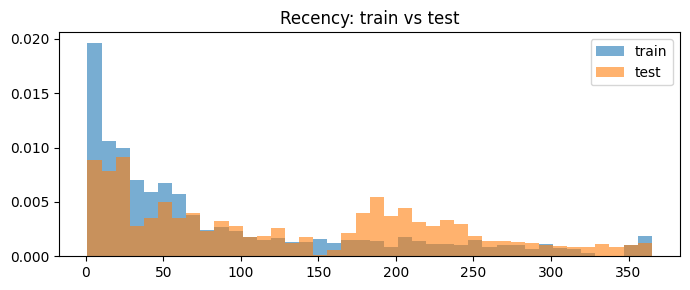

In [7]:
cmp = pd.concat({"train": rfm_train.describe().loc[["mean", "25%", "50%", "75%"]],
                 "test": rfm_test.describe().loc[["mean", "25%", "50%", "75%"]]}, axis=1).round(1)
display(cmp)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(rfm_train["Recency"], bins=40, alpha=0.6, label="train", density=True)
ax.hist(rfm_test["Recency"], bins=40, alpha=0.6, label="test", density=True)
ax.set_title("Recency: train vs test"); ax.legend()
plt.tight_layout()

## What we learned

- 4,242 train and 4,326 test customers, no missing values, and our hand check matches the function.
- All three features relate to the future in the expected direction (Recency negative, Frequency and Monetary positive). Rank correlations with the target are about 0.4-0.6, in both train and test.
- **Frequency and Monetary are strongly related to each other** (big spenders usually buy often). They carry overlapping information.
- **Recency shifts between train and test** (mean about 88 days vs 131): a seasonal effect of the June cutoff. A model that leans on Recency may see a different mix in test.
- 14 train / 9 test customers have `Monetary <= 0`.

**Next (step 5):** look closely at the target (many zeros, negatives, huge values) and decide how to handle it. Then more features can come, one at a time.